In [57]:
import numpy as np
import pandas as pd
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torchmetrics import MetricCollection, Accuracy, Precision, Recall, F1Score

In [70]:
df = pd.read_csv("mobile.csv") 

X = df.drop("price_range", axis=1) 
y = df["price_range"]
print(len(df))
print(df.value_counts(y))

2000
price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64


In [71]:
print(df.head())

   battery_power  blue  clock_speed  dual_sim  fc  four_g  int_memory  m_dep  \
0            842     0          2.2         0   1       0           7    0.6   
1           1021     1          0.5         1   0       1          53    0.7   
2            563     1          0.5         1   2       1          41    0.9   
3            615     1          2.5         0   0       0          10    0.8   
4           1821     1          1.2         0  13       1          44    0.6   

   mobile_wt  n_cores  ...  px_height  px_width   ram  sc_h  sc_w  talk_time  \
0        188        2  ...         20       756  2549     9     7         19   
1        136        3  ...        905      1988  2631    17     3          7   
2        145        5  ...       1263      1716  2603    11     2          9   
3        131        6  ...       1216      1786  2769    16     8         11   
4        141        2  ...       1208      1212  1411     8     2         15   

   three_g  touch_screen  wifi  price_

In [59]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=101)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.22, random_state=101)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [60]:
X_train_scaled_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long) # Для CrossEntropy цілі мають бути long
X_val_scaled_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.long)
X_test_scaled_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

input_dim = X.shape[1]

In [61]:
class MultiLayerPerceptronClassifier(nn.Module):
    def __init__(self, input_dim, activation_function = nn.ReLU):
        super(MultiLayerPerceptronClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64) 
        self.fc2 = nn.Linear(64, 32)        
        self.output = nn.Linear(32, 4) 
        self.activation_function = activation_function()

    def forward(self, x):
        x = self.activation_function(self.fc1(x))
        x = self.activation_function(self.fc2(x))
        x = self.output(x)
        return x

In [62]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0, restore_best_weights=True):
        self.patience = patience 
        self.min_delta = min_delta 
        self.restore_best_weights = restore_best_weights 
        self.best_loss = None
        self.counter = 0
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
            self.counter = 0

In [63]:
def perform_learning(epochs, optimizer_name, activation_function_name, early_stopping_enabled = True):
    activations = {'ReLU': nn.ReLU, 'Sigmoid': nn.Sigmoid, 'Tanh': nn.Tanh}
    activation_function = activations[activation_function_name]
    early_stopping = EarlyStopping()
    model = MultiLayerPerceptronClassifier(input_dim, activation_function)
    optimizers = {
    'SGD': optim.SGD(model.parameters(), lr=0.01),
    'RMSprop': optim.RMSprop(model.parameters(), lr=0.01),
    'Adam': optim.Adam(model.parameters(), lr=0.01),
    'Adadelta': optim.Adadelta(model.parameters(), lr=1.0),
    'Adagrad': optim.Adagrad(model.parameters(), lr=0.01),
    'Adamax': optim.Adamax(model.parameters(), lr=0.01),
    'Nadam': optim.NAdam(model.parameters(), lr=0.01)
    }
    criterion = nn.CrossEntropyLoss()    
    train_loss_history = []
    val_loss_history = []
    optimizer = optimizers[optimizer_name]
    metrics = MetricCollection({
        "accuracy": Accuracy(task="multiclass", num_classes = 4),
        "precision": Precision(task="multiclass", num_classes = 4, average = "macro"),
        "recall": Recall(task="multiclass", num_classes = 4, average = "macro"),
        "f1": F1Score(task="multiclass", num_classes = 4, average = "macro")
    })
    already_stopped = False
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        train_logits = model(X_train_scaled_tensor)
        train_loss = criterion(train_logits, y_train_tensor.squeeze().long())
        train_loss.backward()
        optimizer.step()
        train_loss_history.append(train_loss.item())
        
        model.eval()
        metrics.reset()
        with torch.no_grad():
            val_logits = model(X_val_scaled_tensor)
            val_loss = criterion(val_logits, y_val_tensor.squeeze().long())
            val_probabilites = torch.softmax(val_logits, dim = 1)
            _, val_predictions = torch.max(val_probabilites, 1)
            if not already_stopped:
                step_metrics = metrics(val_predictions, y_val_tensor.squeeze().long())
            val_loss_history.append(val_loss.item())
            early_stopping(val_loss.item(), model)
        
        if early_stopping.early_stop and early_stopping_enabled and not already_stopped:
            print(f"--- [INFO] Early stopping triggered at epoch {epoch+1} for {optimizer_name} ---")
            already_stopped = True
            
        
        if((epoch + 1) % 5 == 0 and not early_stopping.early_stop):
            print(f'Optimizer: {optimizer_name}, Function: {activation_function_name}, Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss.item():.4f}, Validation Loss: {val_loss.item():.4f}, Acc: {step_metrics["accuracy"]}',)
    
    if early_stopping.restore_best_weights:
        model.load_state_dict(early_stopping.best_model_state)
    
    return train_loss_history, val_loss_history, step_metrics, model

In [64]:
optimizer_names = ['SGD', 'RMSprop', 'Adam', 'Adadelta', 'Adagrad', 'Adamax', 'Nadam']
activation_function_names = ['ReLU', 'Sigmoid', 'Tanh']
results = []
best_model = None
best_f1 = 0

Optimizer: SGD, Function: ReLU, Epoch [5/1000], Train Loss: 1.3944, Validation Loss: 1.3970, Acc: 0.20454545319080353
Optimizer: SGD, Function: ReLU, Epoch [10/1000], Train Loss: 1.3937, Validation Loss: 1.3963, Acc: 0.2070707082748413
Optimizer: SGD, Function: ReLU, Epoch [15/1000], Train Loss: 1.3930, Validation Loss: 1.3956, Acc: 0.20454545319080353
Optimizer: SGD, Function: ReLU, Epoch [20/1000], Train Loss: 1.3923, Validation Loss: 1.3949, Acc: 0.20454545319080353
Optimizer: SGD, Function: ReLU, Epoch [25/1000], Train Loss: 1.3916, Validation Loss: 1.3943, Acc: 0.20454545319080353
Optimizer: SGD, Function: ReLU, Epoch [30/1000], Train Loss: 1.3909, Validation Loss: 1.3936, Acc: 0.20454545319080353
Optimizer: SGD, Function: ReLU, Epoch [35/1000], Train Loss: 1.3903, Validation Loss: 1.3930, Acc: 0.20454545319080353
Optimizer: SGD, Function: ReLU, Epoch [40/1000], Train Loss: 1.3896, Validation Loss: 1.3924, Acc: 0.2070707082748413
Optimizer: SGD, Function: ReLU, Epoch [45/1000], Tr

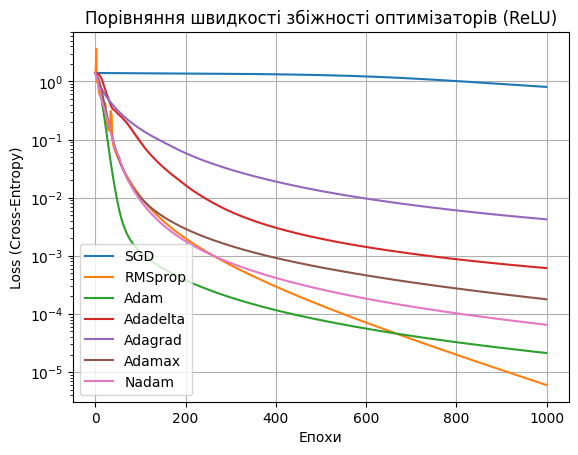

Optimizer: SGD, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3885, Validation Loss: 1.3865, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.3883, Validation Loss: 1.3865, Acc: 0.22727273404598236
--- [INFO] Early stopping triggered at epoch 11 for SGD ---
Optimizer: RMSprop, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3692, Validation Loss: 1.3570, Acc: 0.4040403962135315
Optimizer: RMSprop, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.1599, Validation Loss: 1.1571, Acc: 0.41161617636680603
Optimizer: RMSprop, Function: Sigmoid, Epoch [15/1000], Train Loss: 0.8710, Validation Loss: 0.8442, Acc: 0.6843434572219849
Optimizer: RMSprop, Function: Sigmoid, Epoch [20/1000], Train Loss: 0.7916, Validation Loss: 0.7095, Acc: 0.7626262903213501
Optimizer: RMSprop, Function: Sigmoid, Epoch [25/1000], Train Loss: 0.5809, Validation Loss: 0.5716, Acc: 0.8308081030845642
Optimizer: RMSprop, Function: Sigmoid, Epoch [30/1000], Train Loss: 0.47

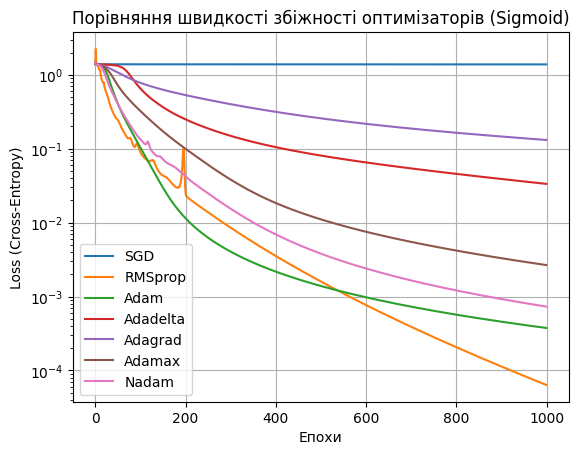

Optimizer: SGD, Function: Tanh, Epoch [5/1000], Train Loss: 1.4065, Validation Loss: 1.4109, Acc: 0.21969696879386902
Optimizer: SGD, Function: Tanh, Epoch [10/1000], Train Loss: 1.4016, Validation Loss: 1.4063, Acc: 0.21969696879386902
Optimizer: SGD, Function: Tanh, Epoch [15/1000], Train Loss: 1.3968, Validation Loss: 1.4018, Acc: 0.2222222238779068
Optimizer: SGD, Function: Tanh, Epoch [20/1000], Train Loss: 1.3921, Validation Loss: 1.3973, Acc: 0.22727273404598236
Optimizer: SGD, Function: Tanh, Epoch [25/1000], Train Loss: 1.3875, Validation Loss: 1.3930, Acc: 0.23232322931289673
Optimizer: SGD, Function: Tanh, Epoch [30/1000], Train Loss: 1.3829, Validation Loss: 1.3887, Acc: 0.2373737394809723
Optimizer: SGD, Function: Tanh, Epoch [35/1000], Train Loss: 1.3784, Validation Loss: 1.3844, Acc: 0.25
Optimizer: SGD, Function: Tanh, Epoch [40/1000], Train Loss: 1.3739, Validation Loss: 1.3802, Acc: 0.2651515007019043
Optimizer: SGD, Function: Tanh, Epoch [45/1000], Train Loss: 1.3694

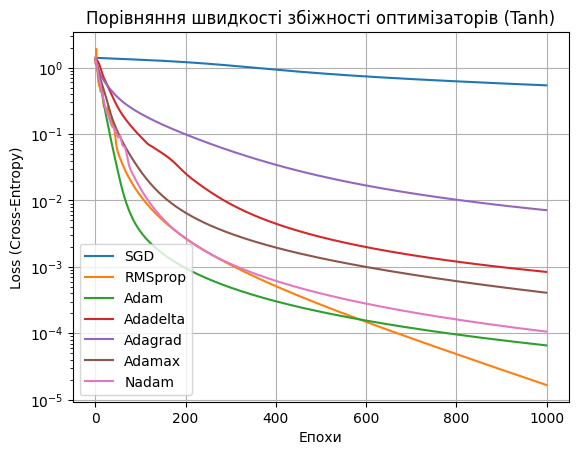

In [65]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        train_loss_history, val_loss_history, final_metrics, model = perform_learning(1000, optimizer, activation_function_name)
        current_f1 = final_metrics["f1"].item()
        if(current_f1 > best_f1):
            best_model = model
            best_f1 = current_f1
        plt.plot(train_loss_history, label=optimizer)
        
        results.append({
            'Activation': activation_function_name,
            'Optimizer': optimizer,
            'Accuracy': final_metrics['accuracy'].item(),
            'Precision': final_metrics['precision'].item(),
            'Recall': final_metrics['recall'].item(),
            'F1-Score': final_metrics['f1'].item()
        })
    plt.title(f'Порівняння швидкості збіжності оптимізаторів ({activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss (Cross-Entropy)')
    plt.yscale('log')  
    plt.legend()
    plt.grid(True)
    plt.show()

In [66]:
results_df = pd.DataFrame(results)
print(results_df.sort_values(by='F1-Score', ascending=False))

   Activation Optimizer  Accuracy  Precision    Recall  F1-Score
10    Sigmoid  Adadelta  0.972222   0.974062  0.970314  0.971625
13    Sigmoid     Nadam  0.969697   0.970685  0.968329  0.969233
8     Sigmoid   RMSprop  0.967172   0.968596  0.966867  0.967422
20       Tanh     Nadam  0.962121   0.964253  0.959708  0.961278
11    Sigmoid   Adagrad  0.962121   0.962209  0.960738  0.961239
16       Tanh      Adam  0.959596   0.960666  0.958238  0.959184
18       Tanh   Adagrad  0.957071   0.958156  0.956021  0.956719
17       Tanh  Adadelta  0.957071   0.959096  0.954476  0.955903
9     Sigmoid      Adam  0.954545   0.954526  0.952796  0.953488
15       Tanh   RMSprop  0.952020   0.951999  0.950133  0.950677
19       Tanh    Adamax  0.949495   0.950304  0.947401  0.948303
12    Sigmoid    Adamax  0.946970   0.945900  0.945205  0.945487
2        ReLU      Adam  0.909091   0.908817  0.907961  0.908295
5        ReLU    Adamax  0.906566   0.907838  0.905160  0.906154
3        ReLU  Adadelta  

In [67]:
def perform_learning_analysis(epochs, optimizer_name, activation_function_name):
    train_loss_history, val_loss_history, _, _ = perform_learning(epochs, optimizer_name, activation_function_name)
    plt.figure(figsize=(10, 6))
    plt.plot(train_loss_history, label='Train Loss')
    plt.plot(val_loss_history, label='Validation Loss', linestyle='--')
    plt.title(f'Аналіз перенавчання ({optimizer_name} + {activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

Optimizer: SGD, Function: ReLU, Epoch [5/1000], Train Loss: 1.3902, Validation Loss: 1.3867, Acc: 0.2904040515422821
Optimizer: SGD, Function: ReLU, Epoch [10/1000], Train Loss: 1.3892, Validation Loss: 1.3858, Acc: 0.2954545319080353
Optimizer: SGD, Function: ReLU, Epoch [15/1000], Train Loss: 1.3882, Validation Loss: 1.3850, Acc: 0.3030303120613098
Optimizer: SGD, Function: ReLU, Epoch [20/1000], Train Loss: 1.3871, Validation Loss: 1.3842, Acc: 0.3055555522441864
Optimizer: SGD, Function: ReLU, Epoch [25/1000], Train Loss: 1.3861, Validation Loss: 1.3834, Acc: 0.3030303120613098
Optimizer: SGD, Function: ReLU, Epoch [30/1000], Train Loss: 1.3851, Validation Loss: 1.3826, Acc: 0.3030303120613098
Optimizer: SGD, Function: ReLU, Epoch [35/1000], Train Loss: 1.3841, Validation Loss: 1.3818, Acc: 0.31060606241226196
Optimizer: SGD, Function: ReLU, Epoch [40/1000], Train Loss: 1.3832, Validation Loss: 1.3811, Acc: 0.31060606241226196
Optimizer: SGD, Function: ReLU, Epoch [45/1000], Train 

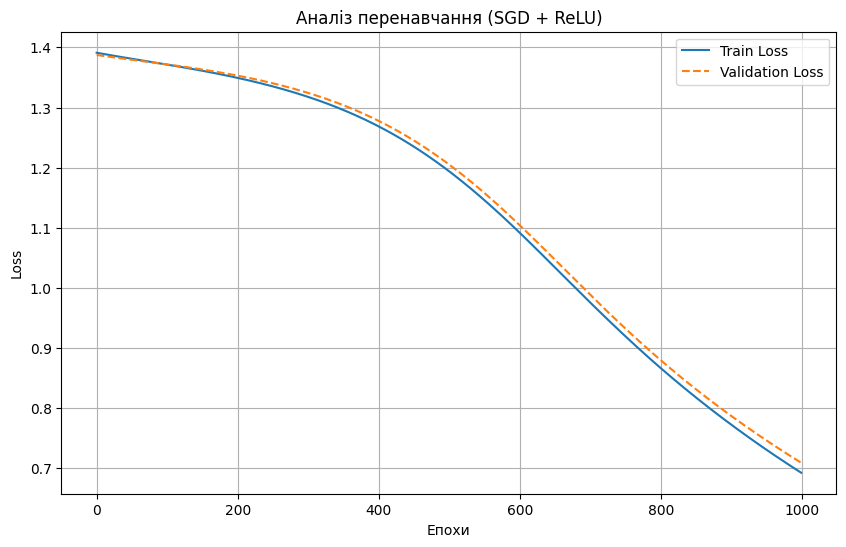

Optimizer: RMSprop, Function: ReLU, Epoch [5/1000], Train Loss: 0.8959, Validation Loss: 1.0954, Acc: 0.39393940567970276
Optimizer: RMSprop, Function: ReLU, Epoch [10/1000], Train Loss: 0.5703, Validation Loss: 0.5985, Acc: 0.7979797720909119
Optimizer: RMSprop, Function: ReLU, Epoch [15/1000], Train Loss: 0.4322, Validation Loss: 0.4435, Acc: 0.8434343338012695
Optimizer: RMSprop, Function: ReLU, Epoch [20/1000], Train Loss: 0.4394, Validation Loss: 0.4650, Acc: 0.7853535413742065
Optimizer: RMSprop, Function: ReLU, Epoch [25/1000], Train Loss: 0.3239, Validation Loss: 0.3606, Acc: 0.8333333134651184
Optimizer: RMSprop, Function: ReLU, Epoch [30/1000], Train Loss: 0.1491, Validation Loss: 0.2708, Acc: 0.8838383555412292
Optimizer: RMSprop, Function: ReLU, Epoch [35/1000], Train Loss: 0.1256, Validation Loss: 0.2676, Acc: 0.8939393758773804
Optimizer: RMSprop, Function: ReLU, Epoch [40/1000], Train Loss: 0.1830, Validation Loss: 0.3690, Acc: 0.8434343338012695
Optimizer: RMSprop, Func

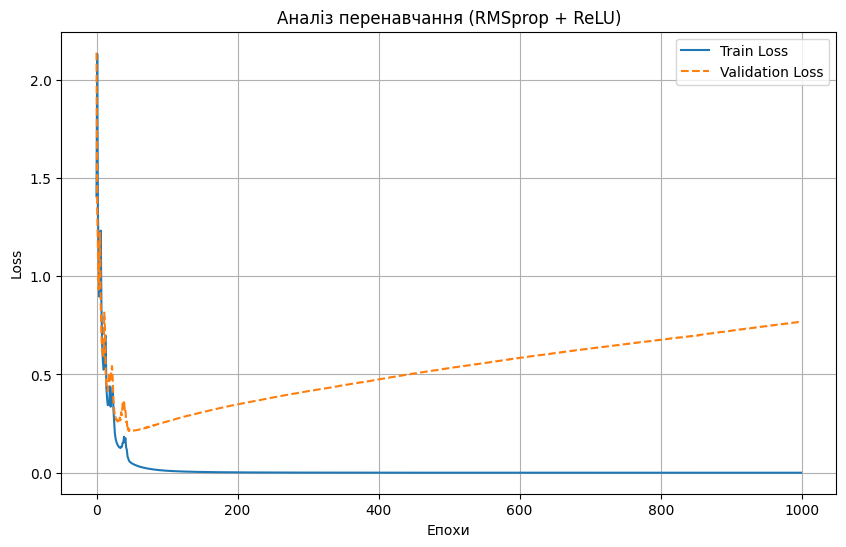

Optimizer: Adam, Function: ReLU, Epoch [5/1000], Train Loss: 1.2100, Validation Loss: 1.1750, Acc: 0.5378788113594055
Optimizer: Adam, Function: ReLU, Epoch [10/1000], Train Loss: 0.8195, Validation Loss: 0.8196, Acc: 0.6565656661987305
Optimizer: Adam, Function: ReLU, Epoch [15/1000], Train Loss: 0.4818, Validation Loss: 0.5387, Acc: 0.7954545617103577
Optimizer: Adam, Function: ReLU, Epoch [20/1000], Train Loss: 0.2539, Validation Loss: 0.3403, Acc: 0.8585858345031738
Optimizer: Adam, Function: ReLU, Epoch [25/1000], Train Loss: 0.1303, Validation Loss: 0.2521, Acc: 0.8914141654968262
Optimizer: Adam, Function: ReLU, Epoch [30/1000], Train Loss: 0.0688, Validation Loss: 0.2322, Acc: 0.8989899158477783
Optimizer: Adam, Function: ReLU, Epoch [35/1000], Train Loss: 0.0360, Validation Loss: 0.2365, Acc: 0.9015151262283325
Optimizer: Adam, Function: ReLU, Epoch [40/1000], Train Loss: 0.0194, Validation Loss: 0.2599, Acc: 0.9065656661987305
--- [INFO] Early stopping triggered at epoch 42 f

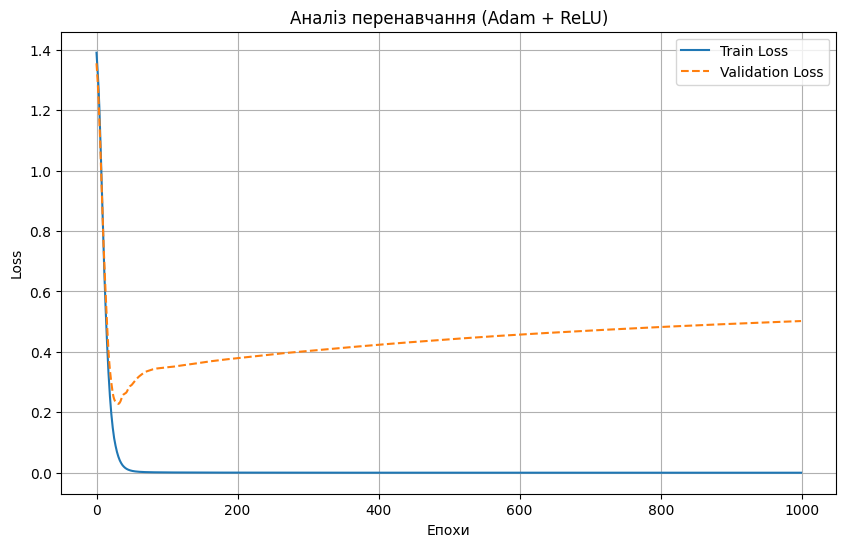

Optimizer: Adadelta, Function: ReLU, Epoch [5/1000], Train Loss: 1.3496, Validation Loss: 1.3460, Acc: 0.4015151560306549
Optimizer: Adadelta, Function: ReLU, Epoch [10/1000], Train Loss: 1.2642, Validation Loss: 1.2553, Acc: 0.49494948983192444
Optimizer: Adadelta, Function: ReLU, Epoch [15/1000], Train Loss: 1.0789, Validation Loss: 1.0593, Acc: 0.5479797720909119
Optimizer: Adadelta, Function: ReLU, Epoch [20/1000], Train Loss: 0.8292, Validation Loss: 0.8174, Acc: 0.6994949579238892
Optimizer: Adadelta, Function: ReLU, Epoch [25/1000], Train Loss: 0.6283, Validation Loss: 0.6369, Acc: 0.7929292917251587
Optimizer: Adadelta, Function: ReLU, Epoch [30/1000], Train Loss: 0.4812, Validation Loss: 0.5097, Acc: 0.8333333134651184
Optimizer: Adadelta, Function: ReLU, Epoch [35/1000], Train Loss: 0.3719, Validation Loss: 0.4178, Acc: 0.8636363744735718
Optimizer: Adadelta, Function: ReLU, Epoch [40/1000], Train Loss: 0.3070, Validation Loss: 0.3854, Acc: 0.8636363744735718
Optimizer: Adade

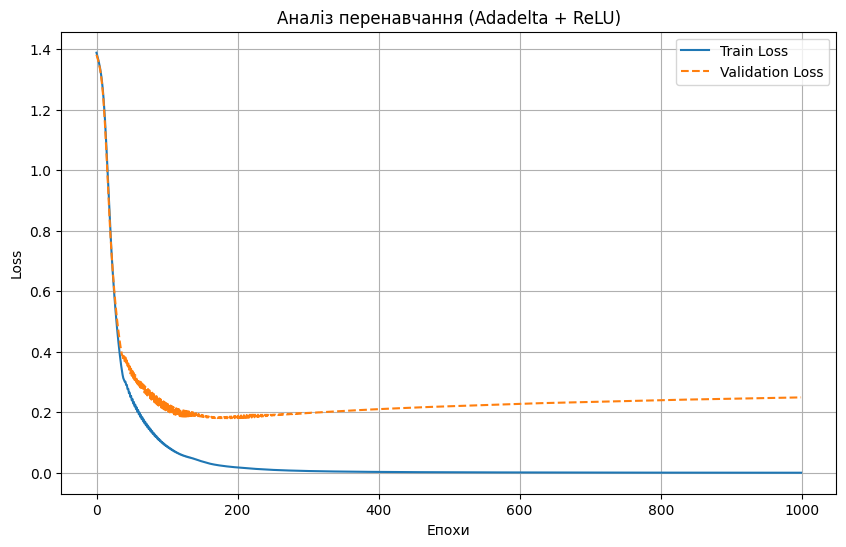

Optimizer: Adagrad, Function: ReLU, Epoch [5/1000], Train Loss: 1.2146, Validation Loss: 1.1784, Acc: 0.5454545617103577
Optimizer: Adagrad, Function: ReLU, Epoch [10/1000], Train Loss: 0.9593, Validation Loss: 0.9618, Acc: 0.6742424368858337
Optimizer: Adagrad, Function: ReLU, Epoch [15/1000], Train Loss: 0.7897, Validation Loss: 0.8138, Acc: 0.7171717286109924
Optimizer: Adagrad, Function: ReLU, Epoch [20/1000], Train Loss: 0.6715, Validation Loss: 0.7177, Acc: 0.8030303120613098
Optimizer: Adagrad, Function: ReLU, Epoch [25/1000], Train Loss: 0.5817, Validation Loss: 0.6429, Acc: 0.8030303120613098
Optimizer: Adagrad, Function: ReLU, Epoch [30/1000], Train Loss: 0.5111, Validation Loss: 0.5850, Acc: 0.8459596037864685
Optimizer: Adagrad, Function: ReLU, Epoch [35/1000], Train Loss: 0.4535, Validation Loss: 0.5357, Acc: 0.8535353541374207
Optimizer: Adagrad, Function: ReLU, Epoch [40/1000], Train Loss: 0.4060, Validation Loss: 0.5005, Acc: 0.8585858345031738
Optimizer: Adagrad, Funct

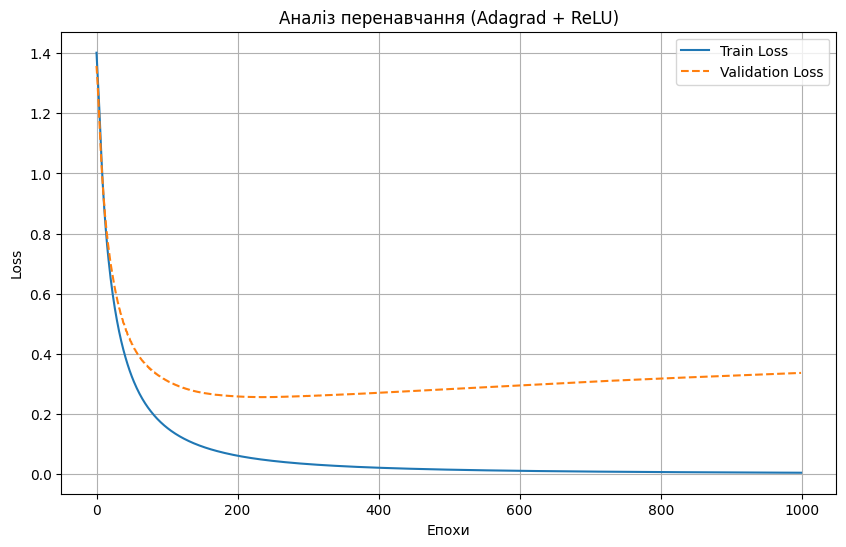

Optimizer: Adamax, Function: ReLU, Epoch [5/1000], Train Loss: 1.2317, Validation Loss: 1.2085, Acc: 0.5176767706871033
Optimizer: Adamax, Function: ReLU, Epoch [10/1000], Train Loss: 0.9590, Validation Loss: 0.9530, Acc: 0.5934343338012695
Optimizer: Adamax, Function: ReLU, Epoch [15/1000], Train Loss: 0.6880, Validation Loss: 0.7179, Acc: 0.6868686676025391
Optimizer: Adamax, Function: ReLU, Epoch [20/1000], Train Loss: 0.4806, Validation Loss: 0.5332, Acc: 0.8131313323974609
Optimizer: Adamax, Function: ReLU, Epoch [25/1000], Train Loss: 0.3291, Validation Loss: 0.4027, Acc: 0.8712121248245239
Optimizer: Adamax, Function: ReLU, Epoch [30/1000], Train Loss: 0.2198, Validation Loss: 0.3100, Acc: 0.8964646458625793
Optimizer: Adamax, Function: ReLU, Epoch [35/1000], Train Loss: 0.1504, Validation Loss: 0.2571, Acc: 0.9116161465644836
Optimizer: Adamax, Function: ReLU, Epoch [40/1000], Train Loss: 0.1056, Validation Loss: 0.2288, Acc: 0.9166666865348816
Optimizer: Adamax, Function: ReLU

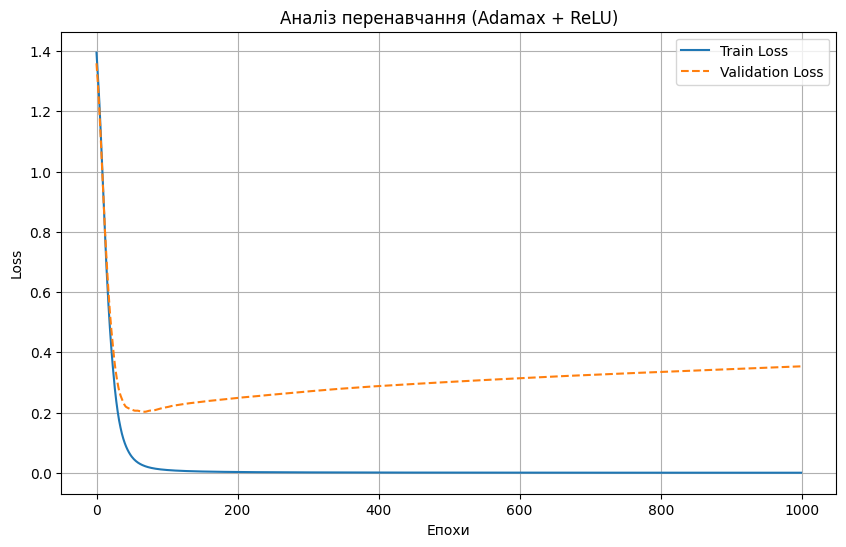

Optimizer: Nadam, Function: ReLU, Epoch [5/1000], Train Loss: 1.1338, Validation Loss: 1.0608, Acc: 0.5959596037864685
Optimizer: Nadam, Function: ReLU, Epoch [10/1000], Train Loss: 0.7337, Validation Loss: 0.8126, Acc: 0.6035353541374207
Optimizer: Nadam, Function: ReLU, Epoch [15/1000], Train Loss: 0.4824, Validation Loss: 0.5163, Acc: 0.8459596037864685
Optimizer: Nadam, Function: ReLU, Epoch [20/1000], Train Loss: 0.3492, Validation Loss: 0.4250, Acc: 0.8131313323974609
Optimizer: Nadam, Function: ReLU, Epoch [25/1000], Train Loss: 0.2542, Validation Loss: 0.3369, Acc: 0.8661616444587708
Optimizer: Nadam, Function: ReLU, Epoch [30/1000], Train Loss: 0.1882, Validation Loss: 0.2975, Acc: 0.8762626051902771
Optimizer: Nadam, Function: ReLU, Epoch [35/1000], Train Loss: 0.1170, Validation Loss: 0.2326, Acc: 0.9065656661987305
Optimizer: Nadam, Function: ReLU, Epoch [40/1000], Train Loss: 0.0864, Validation Loss: 0.2259, Acc: 0.9065656661987305
Optimizer: Nadam, Function: ReLU, Epoch [

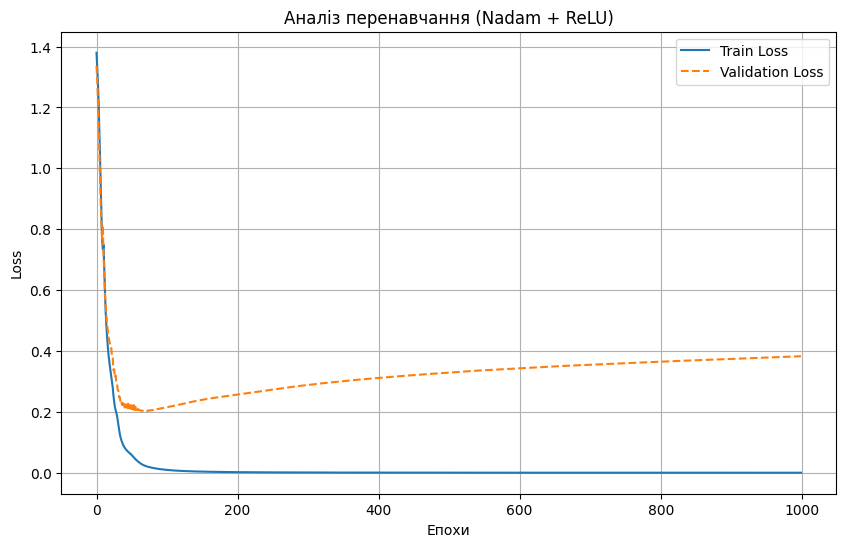

Optimizer: SGD, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3977, Validation Loss: 1.4044, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.3955, Validation Loss: 1.4013, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [15/1000], Train Loss: 1.3937, Validation Loss: 1.3989, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [20/1000], Train Loss: 1.3924, Validation Loss: 1.3969, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [25/1000], Train Loss: 1.3914, Validation Loss: 1.3953, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [30/1000], Train Loss: 1.3906, Validation Loss: 1.3940, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [35/1000], Train Loss: 1.3900, Validation Loss: 1.3930, Acc: 0.21969696879386902
Optimizer: SGD, Function: Sigmoid, Epoch [40/1000], Train Loss: 1.3895, Validation Loss: 1.3921, Acc: 0.21969696879386902
Optimizer: SGD, Function:

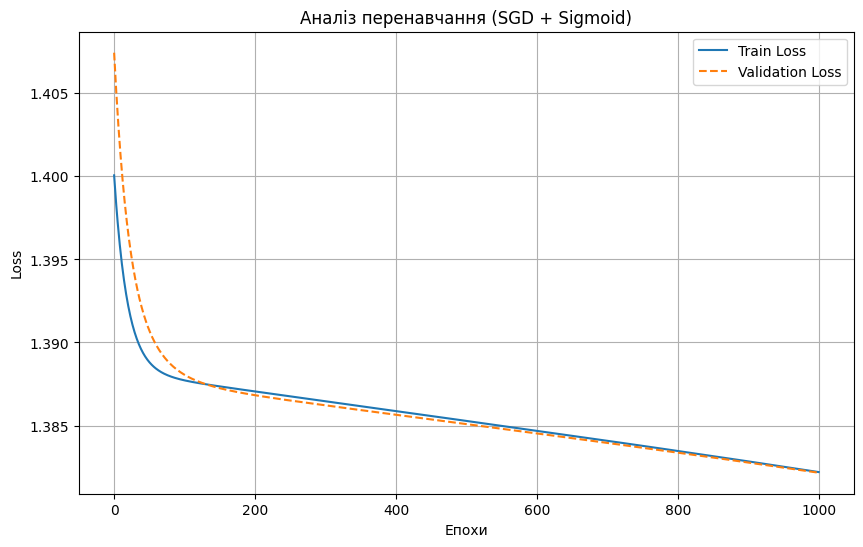

Optimizer: RMSprop, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3735, Validation Loss: 1.3676, Acc: 0.3333333432674408
Optimizer: RMSprop, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.2213, Validation Loss: 1.1692, Acc: 0.5227272510528564
Optimizer: RMSprop, Function: Sigmoid, Epoch [15/1000], Train Loss: 0.9845, Validation Loss: 0.8832, Acc: 0.6439393758773804
Optimizer: RMSprop, Function: Sigmoid, Epoch [20/1000], Train Loss: 0.7512, Validation Loss: 0.7439, Acc: 0.7803030014038086
Optimizer: RMSprop, Function: Sigmoid, Epoch [25/1000], Train Loss: 0.6054, Validation Loss: 0.5825, Acc: 0.8611111044883728
Optimizer: RMSprop, Function: Sigmoid, Epoch [30/1000], Train Loss: 0.5002, Validation Loss: 0.4881, Acc: 0.8964646458625793
Optimizer: RMSprop, Function: Sigmoid, Epoch [35/1000], Train Loss: 0.4174, Validation Loss: 0.4181, Acc: 0.9368686676025391
Optimizer: RMSprop, Function: Sigmoid, Epoch [40/1000], Train Loss: 0.3669, Validation Loss: 0.3743, Acc: 0.8914141654968262
O

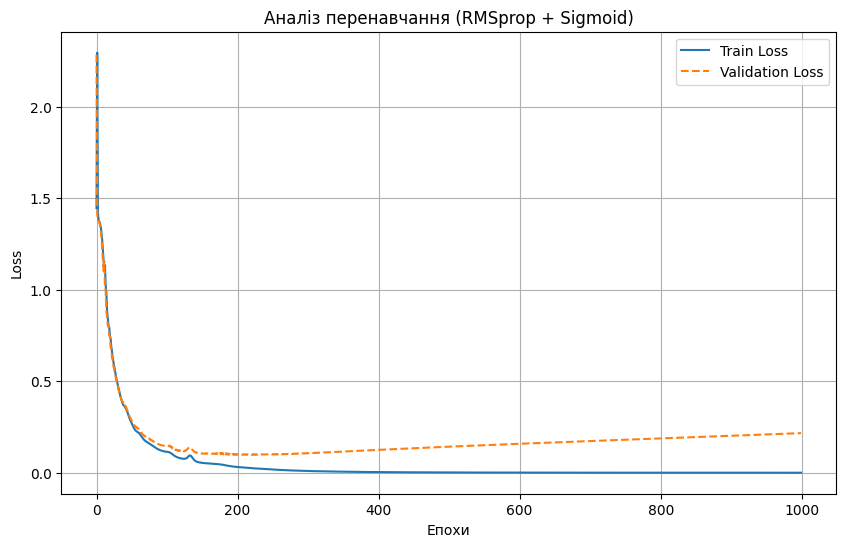

Optimizer: Adam, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3698, Validation Loss: 1.3634, Acc: 0.4747474789619446
Optimizer: Adam, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.3222, Validation Loss: 1.3189, Acc: 0.4444444477558136
Optimizer: Adam, Function: Sigmoid, Epoch [15/1000], Train Loss: 1.2196, Validation Loss: 1.2065, Acc: 0.4747474789619446
Optimizer: Adam, Function: Sigmoid, Epoch [20/1000], Train Loss: 1.0632, Validation Loss: 1.0462, Acc: 0.558080792427063
Optimizer: Adam, Function: Sigmoid, Epoch [25/1000], Train Loss: 0.8683, Validation Loss: 0.8419, Acc: 0.7222222089767456
Optimizer: Adam, Function: Sigmoid, Epoch [30/1000], Train Loss: 0.6887, Validation Loss: 0.6751, Acc: 0.7929292917251587
Optimizer: Adam, Function: Sigmoid, Epoch [35/1000], Train Loss: 0.5611, Validation Loss: 0.5582, Acc: 0.8989899158477783
Optimizer: Adam, Function: Sigmoid, Epoch [40/1000], Train Loss: 0.4605, Validation Loss: 0.4626, Acc: 0.9318181872367859
Optimizer: Adam, Function:

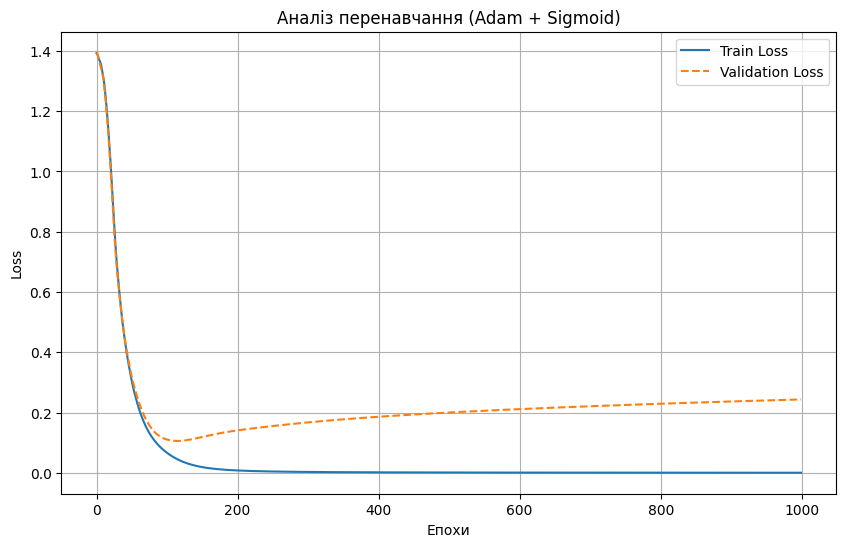

Optimizer: Adadelta, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3970, Validation Loss: 1.3916, Acc: 0.26767677068710327
Optimizer: Adadelta, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.3827, Validation Loss: 1.3820, Acc: 0.30050504207611084
Optimizer: Adadelta, Function: Sigmoid, Epoch [15/1000], Train Loss: 1.3794, Validation Loss: 1.3794, Acc: 0.3207070827484131
Optimizer: Adadelta, Function: Sigmoid, Epoch [20/1000], Train Loss: 1.3768, Validation Loss: 1.3768, Acc: 0.3611111044883728
Optimizer: Adadelta, Function: Sigmoid, Epoch [25/1000], Train Loss: 1.3735, Validation Loss: 1.3735, Acc: 0.44949495792388916
Optimizer: Adadelta, Function: Sigmoid, Epoch [30/1000], Train Loss: 1.3691, Validation Loss: 1.3689, Acc: 0.47979798913002014
Optimizer: Adadelta, Function: Sigmoid, Epoch [35/1000], Train Loss: 1.3633, Validation Loss: 1.3630, Acc: 0.5202020406723022
Optimizer: Adadelta, Function: Sigmoid, Epoch [40/1000], Train Loss: 1.3550, Validation Loss: 1.3540, Acc: 0.525252

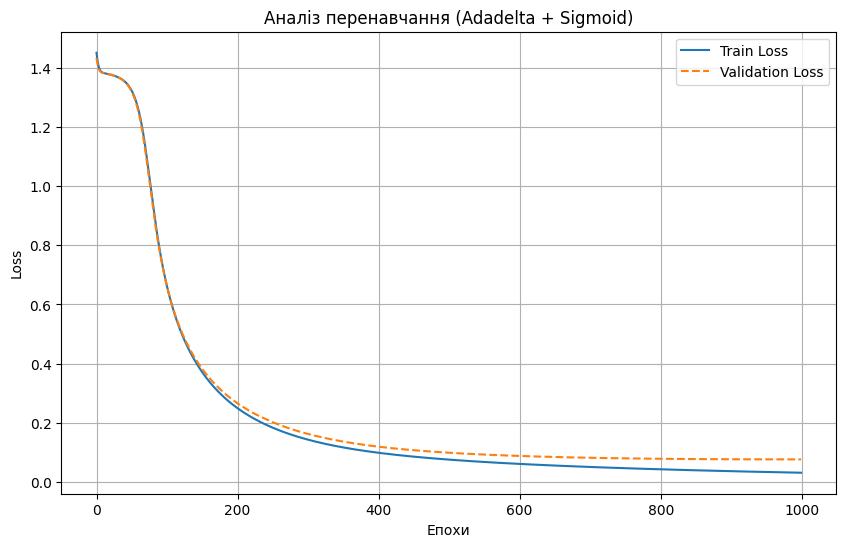

Optimizer: Adagrad, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3732, Validation Loss: 1.3721, Acc: 0.29797980189323425
Optimizer: Adagrad, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.3513, Validation Loss: 1.3492, Acc: 0.4469696879386902
Optimizer: Adagrad, Function: Sigmoid, Epoch [15/1000], Train Loss: 1.3201, Validation Loss: 1.3182, Acc: 0.47979798913002014
Optimizer: Adagrad, Function: Sigmoid, Epoch [20/1000], Train Loss: 1.2802, Validation Loss: 1.2795, Acc: 0.4974747598171234
Optimizer: Adagrad, Function: Sigmoid, Epoch [25/1000], Train Loss: 1.2350, Validation Loss: 1.2356, Acc: 0.5050504803657532
Optimizer: Adagrad, Function: Sigmoid, Epoch [30/1000], Train Loss: 1.1877, Validation Loss: 1.1888, Acc: 0.5277777910232544
Optimizer: Adagrad, Function: Sigmoid, Epoch [35/1000], Train Loss: 1.1402, Validation Loss: 1.1409, Acc: 0.5808081030845642
Optimizer: Adagrad, Function: Sigmoid, Epoch [40/1000], Train Loss: 1.0932, Validation Loss: 1.0932, Acc: 0.6136363744735718

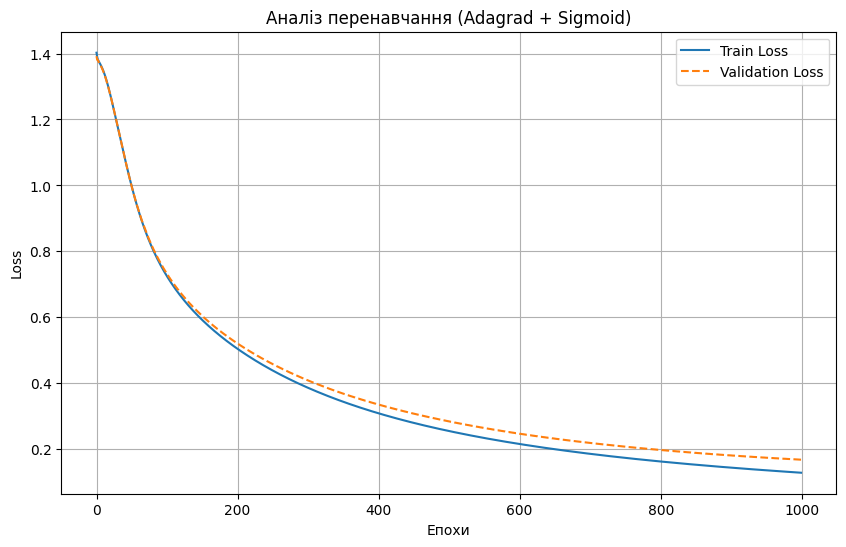

Optimizer: Adamax, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3855, Validation Loss: 1.3779, Acc: 0.2525252401828766
Optimizer: Adamax, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.3577, Validation Loss: 1.3595, Acc: 0.3585858643054962
Optimizer: Adamax, Function: Sigmoid, Epoch [15/1000], Train Loss: 1.3284, Validation Loss: 1.3304, Acc: 0.3484848439693451
Optimizer: Adamax, Function: Sigmoid, Epoch [20/1000], Train Loss: 1.2769, Validation Loss: 1.2799, Acc: 0.43939393758773804
Optimizer: Adamax, Function: Sigmoid, Epoch [25/1000], Train Loss: 1.2084, Validation Loss: 1.2110, Acc: 0.46212121844291687
Optimizer: Adamax, Function: Sigmoid, Epoch [30/1000], Train Loss: 1.1203, Validation Loss: 1.1209, Acc: 0.5277777910232544
Optimizer: Adamax, Function: Sigmoid, Epoch [35/1000], Train Loss: 1.0184, Validation Loss: 1.0107, Acc: 0.6010100841522217
Optimizer: Adamax, Function: Sigmoid, Epoch [40/1000], Train Loss: 0.9013, Validation Loss: 0.8865, Acc: 0.6515151262283325
Optimiz

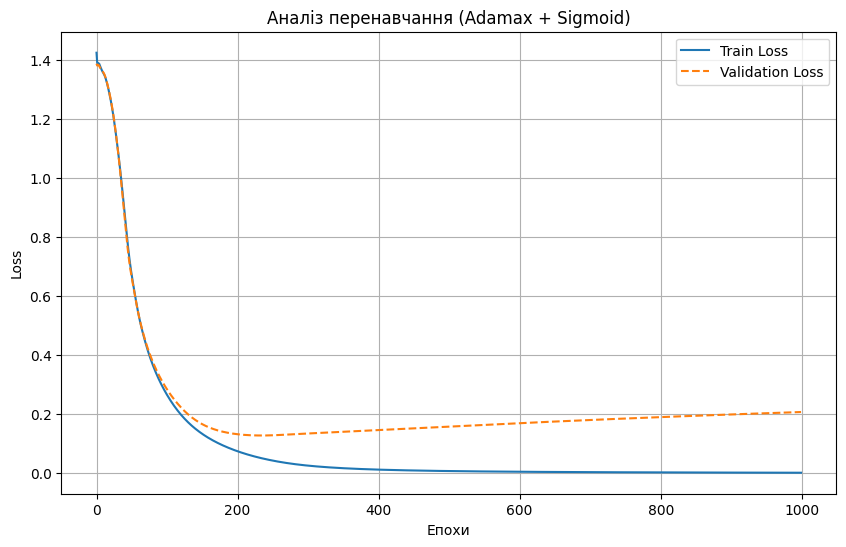

Optimizer: Nadam, Function: Sigmoid, Epoch [5/1000], Train Loss: 1.3740, Validation Loss: 1.3695, Acc: 0.39393940567970276
Optimizer: Nadam, Function: Sigmoid, Epoch [10/1000], Train Loss: 1.3325, Validation Loss: 1.3226, Acc: 0.49242424964904785
Optimizer: Nadam, Function: Sigmoid, Epoch [15/1000], Train Loss: 1.2242, Validation Loss: 1.1983, Acc: 0.48232322931289673
Optimizer: Nadam, Function: Sigmoid, Epoch [20/1000], Train Loss: 1.0509, Validation Loss: 1.0299, Acc: 0.6161616444587708
Optimizer: Nadam, Function: Sigmoid, Epoch [25/1000], Train Loss: 0.8715, Validation Loss: 0.8449, Acc: 0.7196969985961914
Optimizer: Nadam, Function: Sigmoid, Epoch [30/1000], Train Loss: 0.7169, Validation Loss: 0.7054, Acc: 0.8510100841522217
Optimizer: Nadam, Function: Sigmoid, Epoch [35/1000], Train Loss: 0.5983, Validation Loss: 0.5936, Acc: 0.9090909361839294
Optimizer: Nadam, Function: Sigmoid, Epoch [40/1000], Train Loss: 0.5080, Validation Loss: 0.5087, Acc: 0.9343434572219849
Optimizer: Nad

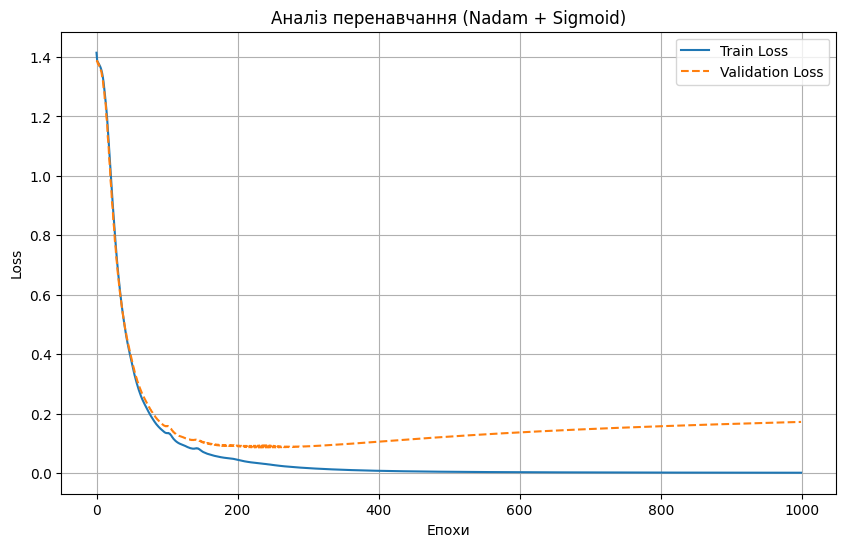

Optimizer: SGD, Function: Tanh, Epoch [5/1000], Train Loss: 1.3943, Validation Loss: 1.3928, Acc: 0.2752525210380554
Optimizer: SGD, Function: Tanh, Epoch [10/1000], Train Loss: 1.3900, Validation Loss: 1.3890, Acc: 0.2954545319080353
Optimizer: SGD, Function: Tanh, Epoch [15/1000], Train Loss: 1.3857, Validation Loss: 1.3851, Acc: 0.3156565725803375
Optimizer: SGD, Function: Tanh, Epoch [20/1000], Train Loss: 1.3815, Validation Loss: 1.3813, Acc: 0.3232323229312897
Optimizer: SGD, Function: Tanh, Epoch [25/1000], Train Loss: 1.3774, Validation Loss: 1.3776, Acc: 0.3358585834503174
Optimizer: SGD, Function: Tanh, Epoch [30/1000], Train Loss: 1.3732, Validation Loss: 1.3738, Acc: 0.34090909361839294
Optimizer: SGD, Function: Tanh, Epoch [35/1000], Train Loss: 1.3691, Validation Loss: 1.3701, Acc: 0.35606059432029724
Optimizer: SGD, Function: Tanh, Epoch [40/1000], Train Loss: 1.3650, Validation Loss: 1.3664, Acc: 0.3737373650074005
Optimizer: SGD, Function: Tanh, Epoch [45/1000], Train 

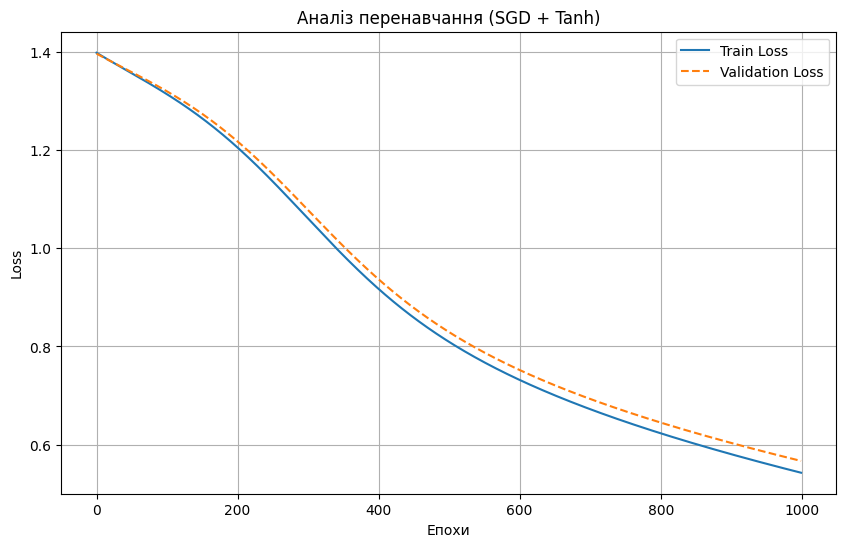

Optimizer: RMSprop, Function: Tanh, Epoch [5/1000], Train Loss: 0.8510, Validation Loss: 0.7533, Acc: 0.6338383555412292
Optimizer: RMSprop, Function: Tanh, Epoch [10/1000], Train Loss: 0.5327, Validation Loss: 0.6657, Acc: 0.689393937587738
Optimizer: RMSprop, Function: Tanh, Epoch [15/1000], Train Loss: 0.3865, Validation Loss: 0.4490, Acc: 0.8030303120613098
Optimizer: RMSprop, Function: Tanh, Epoch [20/1000], Train Loss: 0.2567, Validation Loss: 0.2911, Acc: 0.8914141654968262
Optimizer: RMSprop, Function: Tanh, Epoch [25/1000], Train Loss: 0.2670, Validation Loss: 0.3129, Acc: 0.8712121248245239
Optimizer: RMSprop, Function: Tanh, Epoch [30/1000], Train Loss: 0.1848, Validation Loss: 0.2625, Acc: 0.9090909361839294
Optimizer: RMSprop, Function: Tanh, Epoch [35/1000], Train Loss: 0.1736, Validation Loss: 0.2506, Acc: 0.8888888955116272
Optimizer: RMSprop, Function: Tanh, Epoch [40/1000], Train Loss: 0.1300, Validation Loss: 0.2206, Acc: 0.9166666865348816
Optimizer: RMSprop, Functi

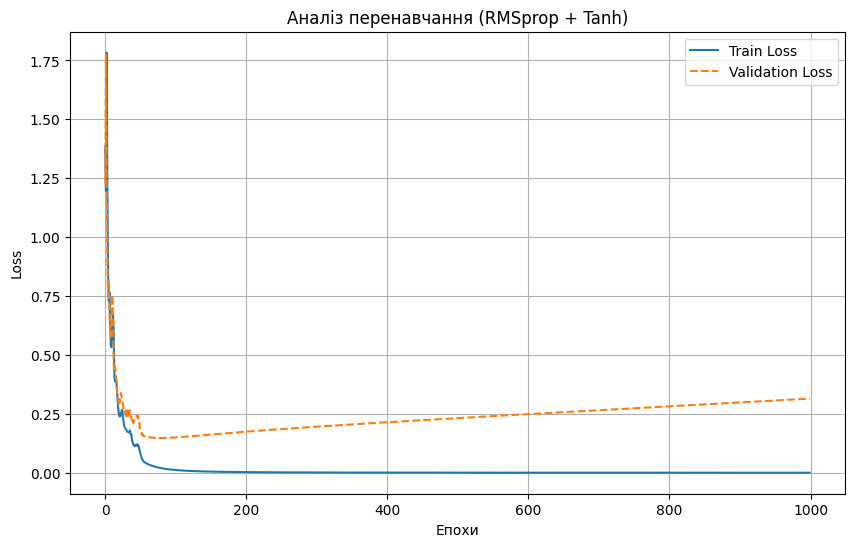

Optimizer: Adam, Function: Tanh, Epoch [5/1000], Train Loss: 1.0872, Validation Loss: 1.0303, Acc: 0.5429292917251587
Optimizer: Adam, Function: Tanh, Epoch [10/1000], Train Loss: 0.6960, Validation Loss: 0.6957, Acc: 0.6666666865348816
Optimizer: Adam, Function: Tanh, Epoch [15/1000], Train Loss: 0.5011, Validation Loss: 0.5029, Acc: 0.8131313323974609
Optimizer: Adam, Function: Tanh, Epoch [20/1000], Train Loss: 0.3243, Validation Loss: 0.3386, Acc: 0.9267676472663879
Optimizer: Adam, Function: Tanh, Epoch [25/1000], Train Loss: 0.2033, Validation Loss: 0.2306, Acc: 0.941919207572937
Optimizer: Adam, Function: Tanh, Epoch [30/1000], Train Loss: 0.1394, Validation Loss: 0.1764, Acc: 0.9621211886405945
Optimizer: Adam, Function: Tanh, Epoch [35/1000], Train Loss: 0.0961, Validation Loss: 0.1411, Acc: 0.9545454382896423
Optimizer: Adam, Function: Tanh, Epoch [40/1000], Train Loss: 0.0657, Validation Loss: 0.1253, Acc: 0.9621211886405945
Optimizer: Adam, Function: Tanh, Epoch [45/1000], 

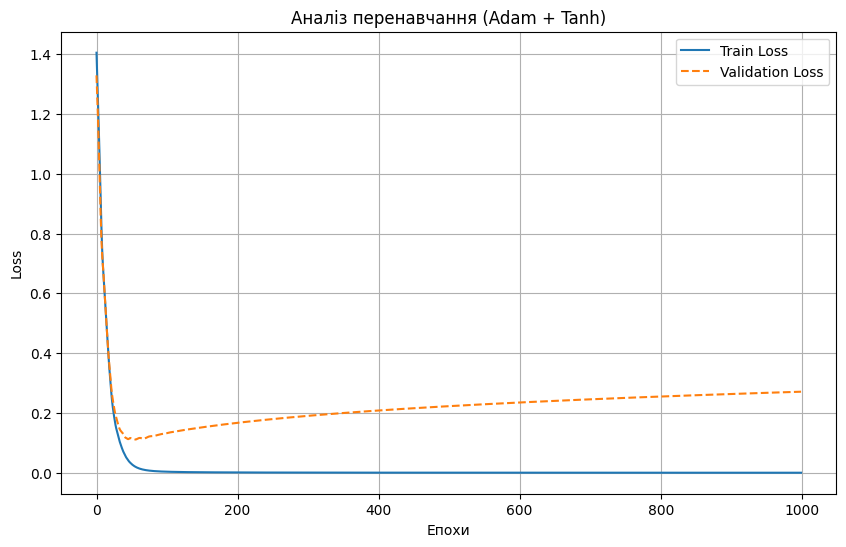

Optimizer: Adadelta, Function: Tanh, Epoch [5/1000], Train Loss: 1.2808, Validation Loss: 1.2581, Acc: 0.5277777910232544
Optimizer: Adadelta, Function: Tanh, Epoch [10/1000], Train Loss: 1.0880, Validation Loss: 1.0577, Acc: 0.6262626051902771
Optimizer: Adadelta, Function: Tanh, Epoch [15/1000], Train Loss: 0.8590, Validation Loss: 0.8417, Acc: 0.6691918969154358
Optimizer: Adadelta, Function: Tanh, Epoch [20/1000], Train Loss: 0.7036, Validation Loss: 0.7027, Acc: 0.7272727489471436
Optimizer: Adadelta, Function: Tanh, Epoch [25/1000], Train Loss: 0.6006, Validation Loss: 0.6064, Acc: 0.8005050420761108
Optimizer: Adadelta, Function: Tanh, Epoch [30/1000], Train Loss: 0.5118, Validation Loss: 0.5212, Acc: 0.8636363744735718
Optimizer: Adadelta, Function: Tanh, Epoch [35/1000], Train Loss: 0.4304, Validation Loss: 0.4436, Acc: 0.9040403962135315
Optimizer: Adadelta, Function: Tanh, Epoch [40/1000], Train Loss: 0.3607, Validation Loss: 0.3783, Acc: 0.9242424368858337
Optimizer: Adadel

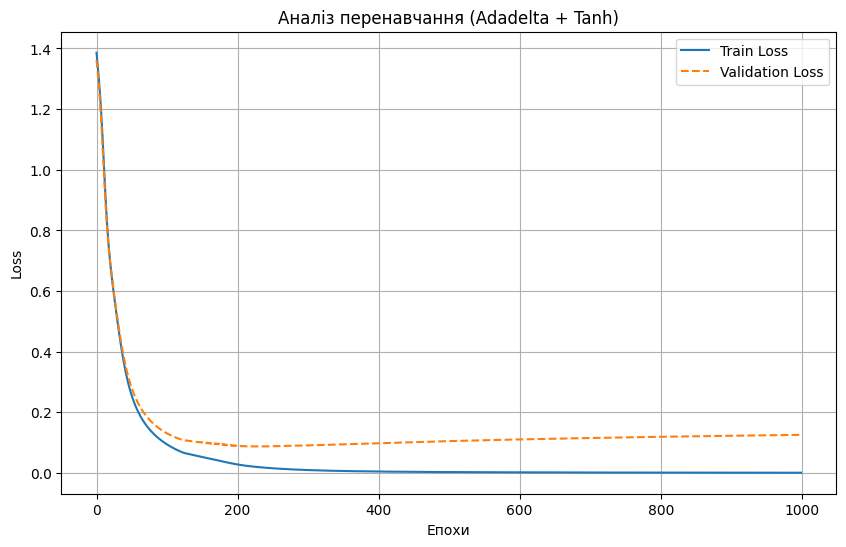

Optimizer: Adagrad, Function: Tanh, Epoch [5/1000], Train Loss: 1.1401, Validation Loss: 1.0975, Acc: 0.560606062412262
Optimizer: Adagrad, Function: Tanh, Epoch [10/1000], Train Loss: 0.8842, Validation Loss: 0.8763, Acc: 0.7045454382896423
Optimizer: Adagrad, Function: Tanh, Epoch [15/1000], Train Loss: 0.7410, Validation Loss: 0.7477, Acc: 0.7676767706871033
Optimizer: Adagrad, Function: Tanh, Epoch [20/1000], Train Loss: 0.6450, Validation Loss: 0.6616, Acc: 0.8030303120613098
Optimizer: Adagrad, Function: Tanh, Epoch [25/1000], Train Loss: 0.5711, Validation Loss: 0.5906, Acc: 0.8560606241226196
Optimizer: Adagrad, Function: Tanh, Epoch [30/1000], Train Loss: 0.5100, Validation Loss: 0.5337, Acc: 0.8838383555412292
Optimizer: Adagrad, Function: Tanh, Epoch [35/1000], Train Loss: 0.4595, Validation Loss: 0.4823, Acc: 0.9116161465644836
Optimizer: Adagrad, Function: Tanh, Epoch [40/1000], Train Loss: 0.4166, Validation Loss: 0.4437, Acc: 0.9116161465644836
Optimizer: Adagrad, Functi

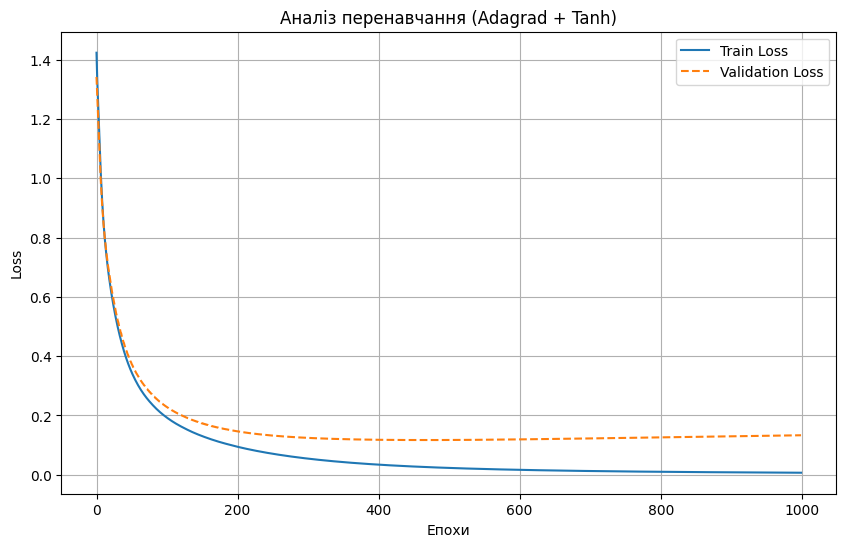

Optimizer: Adamax, Function: Tanh, Epoch [5/1000], Train Loss: 1.0612, Validation Loss: 1.0231, Acc: 0.5732323527336121
Optimizer: Adamax, Function: Tanh, Epoch [10/1000], Train Loss: 0.7504, Validation Loss: 0.7555, Acc: 0.6944444179534912
Optimizer: Adamax, Function: Tanh, Epoch [15/1000], Train Loss: 0.5945, Validation Loss: 0.6211, Acc: 0.7121211886405945
Optimizer: Adamax, Function: Tanh, Epoch [20/1000], Train Loss: 0.4631, Validation Loss: 0.4849, Acc: 0.8409090638160706
Optimizer: Adamax, Function: Tanh, Epoch [25/1000], Train Loss: 0.3636, Validation Loss: 0.3888, Acc: 0.9217171669006348
Optimizer: Adamax, Function: Tanh, Epoch [30/1000], Train Loss: 0.2777, Validation Loss: 0.3043, Acc: 0.939393937587738
Optimizer: Adamax, Function: Tanh, Epoch [35/1000], Train Loss: 0.2207, Validation Loss: 0.2548, Acc: 0.9520202279090881
Optimizer: Adamax, Function: Tanh, Epoch [40/1000], Train Loss: 0.1773, Validation Loss: 0.2129, Acc: 0.9570707082748413
Optimizer: Adamax, Function: Tanh,

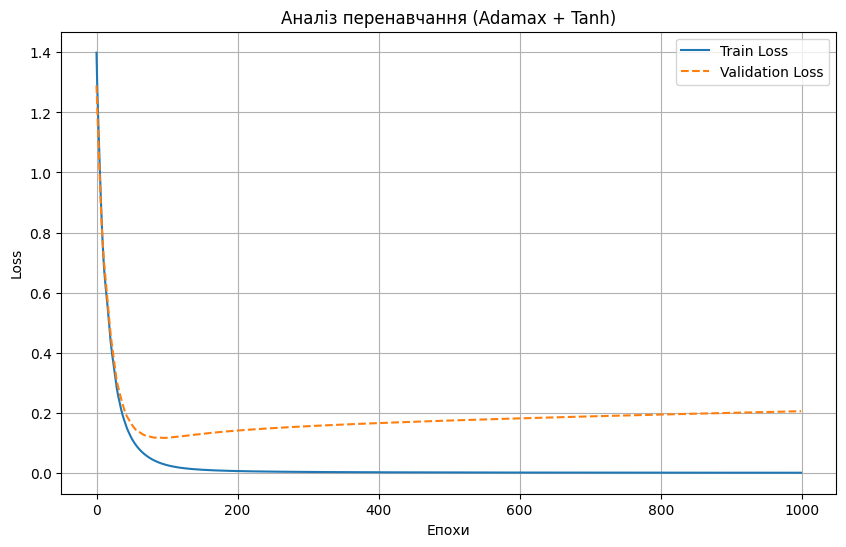

Optimizer: Nadam, Function: Tanh, Epoch [5/1000], Train Loss: 1.0669, Validation Loss: 0.9971, Acc: 0.618686854839325
Optimizer: Nadam, Function: Tanh, Epoch [10/1000], Train Loss: 0.6972, Validation Loss: 0.6670, Acc: 0.7373737096786499
Optimizer: Nadam, Function: Tanh, Epoch [15/1000], Train Loss: 0.4524, Validation Loss: 0.4598, Acc: 0.881313145160675
Optimizer: Nadam, Function: Tanh, Epoch [20/1000], Train Loss: 0.3130, Validation Loss: 0.3292, Acc: 0.9065656661987305
Optimizer: Nadam, Function: Tanh, Epoch [25/1000], Train Loss: 0.2203, Validation Loss: 0.2474, Acc: 0.9267676472663879
Optimizer: Nadam, Function: Tanh, Epoch [30/1000], Train Loss: 0.1846, Validation Loss: 0.2210, Acc: 0.9141414165496826
Optimizer: Nadam, Function: Tanh, Epoch [35/1000], Train Loss: 0.1486, Validation Loss: 0.1914, Acc: 0.9318181872367859
Optimizer: Nadam, Function: Tanh, Epoch [40/1000], Train Loss: 0.1274, Validation Loss: 0.1638, Acc: 0.939393937587738
Optimizer: Nadam, Function: Tanh, Epoch [45/

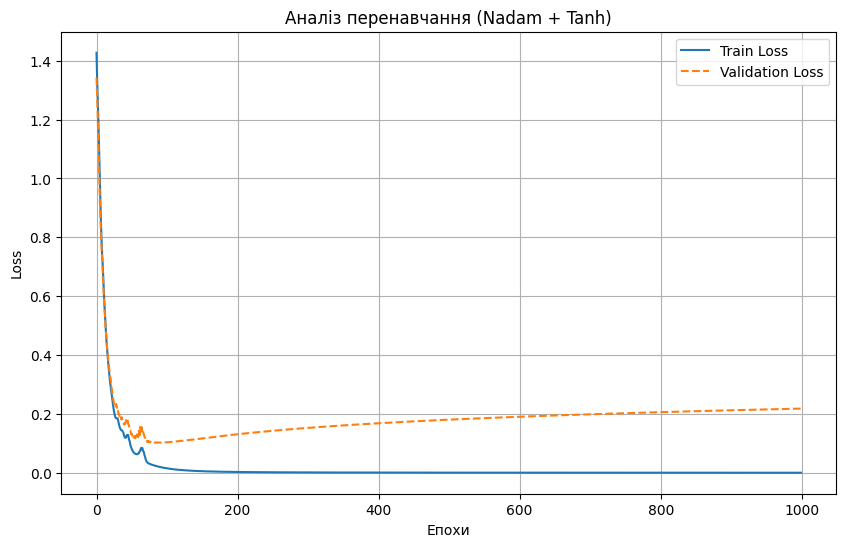

In [68]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        perform_learning_analysis(1000, optimizer, activation_function_name)
        

In [69]:
print("\n" + "="*30)
print("ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Individual Second)")
best_model.eval()
with torch.no_grad():
    test_logits = best_model(X_test_scaled_tensor)
    _, test_predictions = torch.max(test_logits, 1)

from sklearn.metrics import classification_report
print(classification_report(y_test_tensor.squeeze().long(), test_predictions))


ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Individual Second)
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.90      1.00      0.95        46
           2       1.00      0.89      0.94        62
           3       0.93      1.00      0.97        42

    accuracy                           0.96       200
   macro avg       0.96      0.97      0.96       200
weighted avg       0.96      0.96      0.96       200

